<font color = LightBlue Size  = 10>Fatemeh Mohammadi  
 SID: 810199489  
 HW1</font>

# <font color = lightGreen> Problem 1: 
 Food Recommendation System  </font>

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.stats import beta


In [66]:
SID = 810199489

num_arms = ((SID) % 100) % 5 + 2
probabilities = [int(digit)/10 for digit in str(SID)[-num_arms:]]

print(f"Num arms: {num_arms}")
print(f"Probabilities: {probabilities}")

UCB_C = 1

Num arms: 6
Probabilities: [0.1, 0.9, 0.9, 0.4, 0.8, 0.9]


## <font>Thompson Sampling Algorithm </font>

In [41]:
class thompson_sampling:
    def __init__(self, num_arms):
        self.num_arms = num_arms
        self.alpha = np.ones(num_arms)
        self.beta = np.ones(num_arms)

    def select_arm(self):
        samples = [beta.rvs(self.alpha[i], self.beta[i]) for i in range(self.num_arms)]
        return np.argmax(samples)

    def update(self, arm, reward):
        self.alpha[arm] += reward
        self.beta[arm] += (1 - reward)

## <font> Upper Confidence Bound (UCB) Algorithm </font>

The Key Idea of UCB:

For each arm, UCB calculates a score based on the formula:

$
\text{UCB}(a) = \hat{\mu}_a + c \times \sqrt{\frac{\ln t}{N_a}}
$

Where:
- $ \hat{\mu}_a $: The average reward obtained from arm $ a $ so far (this is the **exploitation** term).
- $ c $: A constant that controls the amount of exploration.
- $ t $: The current time step (or number of rounds played).
- $ N_a $: The number of times arm $ a $ has been played so far (this affects **exploration**).

The **confidence interval** $ \sqrt{\frac{\ln t}{N_a}} $ shrinks as you play an arm more frequently, meaning the algorithm becomes more confident about its average reward. Arms that have been tried less often will have larger confidence intervals, giving them a chance to be explored.



In [42]:
class UCB:
    def __init__(self, num_arms, c = UCB_C):
        self.num_arms = num_arms
        self.c = c
        self.t = 0
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)

    def select_arm(self):
        if self.t < self.num_arms:
            return self.t
        else:
            return np.argmax(self.means + self.c * np.sqrt(np.log(self.t) / self.counts))

    def update(self, arm, reward):
        self.t += 1
        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]



## <font> Epsilon-Greedy Algorithm </font>

epsilon ? ro befhamim ya motaghaier?

In [43]:
class epsilon_greedy:
    def __init__(self, num_arms, epsilon = 0.1):
        self.num_arms = num_arms
        self.epsilon = epsilon
        self.t = 0
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)

    def select_arm(self):
        if random.random() > self.epsilon:
            return np.argmax(self.means)
        else:
            return np.random.randint(self.num_arms)

    def update(self, arm, reward):
        self.t += 1
        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]

## <font> Simulation </font>


In [44]:
def simulate(algorithm, probabilities, num_rounds):
    rewards = np.zeros(num_rounds)
    regrets = np.zeros(num_rounds)
    optimal_reward = np.max(probabilities)

    for i in range(num_rounds):
        arm = algorithm.select_arm()
        reward = 1 if random.random() < probabilities[arm] else 0
        algorithm.update(arm, reward)
        rewards[i] = reward
        regrets[i] = optimal_reward - probabilities[arm]

    return rewards, regrets

In [48]:
# Run simulations for each algorithm
num_rounds = 50000
rewards_ts, regrets_ts = simulate(thompson_sampling(num_arms), probabilities, num_rounds)
cumulative_reward_ts = np.cumsum(rewards_ts)
cumulative_regret_ts = np.cumsum(regrets_ts)

rewards_ucb, regrets_ucb = simulate(UCB(num_arms), probabilities, num_rounds)
cumulative_reward_ucb = np.cumsum(rewards_ucb)
cumulative_regret_ucb = np.cumsum(regrets_ucb)

rewards_eg, regrets_eg = simulate(epsilon_greedy(num_arms), probabilities, num_rounds)
cumulative_reward_eg = np.cumsum(rewards_eg)
cumulative_regret_eg = np.cumsum(regrets_eg)

### 

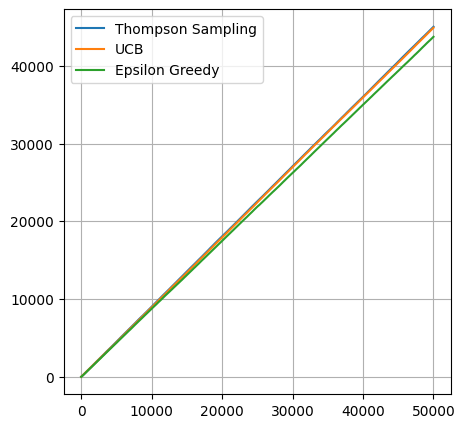

In [64]:
# plot cumulative rewards
plt.figure(figsize=(5, 5))

plt.plot(cumulative_reward_ts, label="Thompson Sampling")
plt.plot(cumulative_reward_ucb, label="UCB")
plt.plot(cumulative_reward_eg, label="Epsilon Greedy")

plt.legend()
plt.grid(True)
plt.show()


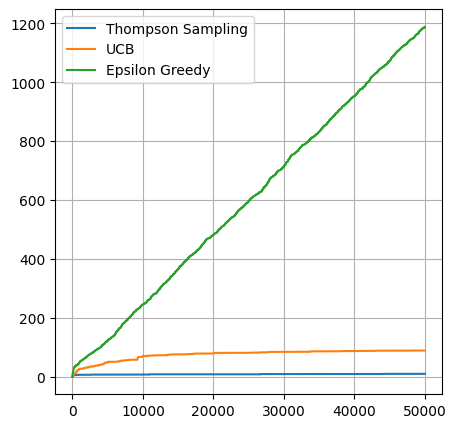

In [65]:
# plot cumulative regrets
plt.figure(figsize=(5, 5))

plt.plot(cumulative_regret_ts, label = "Thompson Sampling")
plt.plot(cumulative_regret_ucb, label = "UCB")
plt.plot(cumulative_regret_eg, label = "Epsilon Greedy")

plt.legend()
plt.grid(True)
plt.show()